<a href="https://colab.research.google.com/github/Joaquin-Lobato-Adinolfi/TP_LMC_F1_Analysis/blob/main/TP_LMC_F1_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Importamos las librerias que se utilizaran**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

**Ahora, importamos el dataset completo desde la pagina, con el formato que nos dan**

Observese, path funcionara para traer y luego leer los csv que contiene la descarga

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«El notebook tiene que poder ejecutarse completo aunque Kaggle no esté disponible. Agregá un respaldo a la descarga con kagglehub que baje los mismos CSV desde otra fuente pública con el mismo esquema.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [2]:
import os, urllib.request

# Descarga oficial desde Kaggle (funciona en Colab)
try:
    import kagglehub
    path = kagglehub.dataset_download("rohanrao/formula-1-world-championship-1950-2020")
except Exception as e:
    # Respaldo: si Kaggle no esta disponible (sin credenciales o sin red), bajamos los mismos CSV
    # (mismo esquema Ergast) desde un espejo publico en GitHub.
    print("No se pudo usar kagglehub:", type(e).__name__, "-> usando espejo de GitHub")
    path = "f1_data"
    os.makedirs(path, exist_ok=True)
    base = "https://raw.githubusercontent.com/TracingInsights/RaceData/main/data/"
    for tabla in ["races", "results", "drivers", "constructors", "qualifying", "status"]:
        destino = f"{path}/{tabla}.csv"
        if not os.path.exists(destino):
            urllib.request.urlretrieve(base + tabla + ".csv", destino)

print("Path to dataset files:", path)

No se pudo usar kagglehub: ModuleNotFoundError -> usando espejo de GitHub


Path to dataset files: f1_data


El dataset contiene muchos csv pero seleccionaremos los necesarios para cumplir con nuestro cometido, necesitando tambien filtrarlos por años principalmente. Para ello, leeremos primero el csv completo y luego dejaremos uno filtrado con los datos necesitados.

**Races**

In [3]:
# Todas las carreras
races_all = pd.read_csv(path + "/races.csv")
races_all

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
0,1,2009,1,1,Australian Grand Prix,2009-03-29,06:00:00,http://en.wikipedia.org/wiki/2009_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
1,2,2009,2,2,Malaysian Grand Prix,2009-04-05,09:00:00,http://en.wikipedia.org/wiki/2009_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
2,3,2009,3,17,Chinese Grand Prix,2009-04-19,07:00:00,http://en.wikipedia.org/wiki/2009_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
3,4,2009,4,3,Bahrain Grand Prix,2009-04-26,12:00:00,http://en.wikipedia.org/wiki/2009_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
4,5,2009,5,4,Spanish Grand Prix,2009-05-10,12:00:00,http://en.wikipedia.org/wiki/2009_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1167,1187,2026,19,32,Mexico City Grand Prix,2026-11-01,20:00:00,https://en.wikipedia.org/wiki/2026_Mexico_City...,2026-10-30,18:30:00,2026-10-30,22:00:00,2026-10-31,17:30:00,2026-10-31,21:00:00,\N,\N
1168,1188,2026,20,18,Brazilian Grand Prix,2026-11-08,17:00:00,https://en.wikipedia.org/wiki/2026_Brazilian_G...,2026-11-06,15:30:00,2026-11-06,19:00:00,2026-11-07,14:30:00,2026-11-07,18:00:00,\N,\N
1169,1189,2026,21,80,Las Vegas Grand Prix,2026-11-22,04:00:00,https://en.wikipedia.org/wiki/2026_Las_Vegas_G...,2026-11-20,00:30:00,2026-11-20,04:00:00,2026-11-21,00:30:00,2026-11-21,04:00:00,\N,\N
1170,1190,2026,22,78,Qatar Grand Prix,2026-11-29,16:00:00,https://en.wikipedia.org/wiki/2026_Qatar_Grand...,2026-11-27,13:30:00,2026-11-27,17:00:00,2026-11-28,14:30:00,2026-11-28,18:00:00,\N,\N


In [4]:
# Las carreras de 2010 a 2024 (las versiones nuevas del dataset ya incluyen 2025, que dejamos afuera)
races = races_all[(races_all["year"] >= 2010) & (races_all["year"] <= 2024)]
races

,raceId,year,round,circuitId,name,date,time,url,fp1_date,fp1_time,fp2_date,fp2_time,fp3_date,fp3_time,quali_date,quali_time,sprint_date,sprint_time
336,337,2010,1,3,Bahrain Grand Prix,2010-03-14,12:00:00,http://en.wikipedia.org/wiki/2010_Bahrain_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
337,338,2010,2,1,Australian Grand Prix,2010-03-28,06:00:00,http://en.wikipedia.org/wiki/2010_Australian_G...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
338,339,2010,3,2,Malaysian Grand Prix,2010-04-04,08:00:00,http://en.wikipedia.org/wiki/2010_Malaysian_Gr...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
339,340,2010,4,17,Chinese Grand Prix,2010-04-18,06:00:00,http://en.wikipedia.org/wiki/2010_Chinese_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
340,341,2010,5,4,Spanish Grand Prix,2010-05-09,12:00:00,http://en.wikipedia.org/wiki/2010_Spanish_Gran...,\N,\N,\N,\N,\N,\N,\N,\N,\N,\N
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1120,1140,2024,20,32,Mexico City Grand Prix,2024-10-27,20:00:00,https://en.wikipedia.org/wiki/2024_Mexico_City...,2024-10-25,18:30:00,2024-10-25,22:00:00,2024-10-26,17:30:00,2024-10-26,21:00:00,\N,\N
1121,1141,2024,21,18,São Paulo Grand Prix,2024-11-03,17:00:00,https://en.wikipedia.org/wiki/2024_S%C3%A3o_Pa...,2024-11-01,14:30:00,\N,\N,\N,\N,2024-11-02,18:00:00,2024-11-02,14:00:00
1122,1142,2024,22,80,Las Vegas Grand Prix,2024-11-23,06:00:00,https://en.wikipedia.org/wiki/2024_Las_Vegas_G...,2024-11-21,02:30:00,2024-11-21,06:00:00,2024-11-22,02:30:00,2024-11-22,06:00:00,\N,\N
1123,1143,2024,23,78,Qatar Grand Prix,2024-12-01,16:00:00,https://en.wikipedia.org/wiki/2024_Qatar_Grand...,2024-11-29,13:30:00,\N,\N,\N,\N,2024-11-30,18:00:00,2024-11-30,14:00:00


**Resultados**

Notese, utilizaremos races para filtrar los datos restantes

In [5]:
# Todos los resultados
results_all = pd.read_csv(path + "/results.csv")
results_all

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.3,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27607,27613,1185,848,3,23,16,18,18,18,0.0,59,\N,5998746,41,12,1:37.436,\N,31
27608,27614,1185,822,216,77,18,19,19,19,0.0,59,+17.347,6138132,30,21,1:40.171,\N,144
27609,27615,1185,840,117,18,21,20,R,20,0.0,36,\N,\N,28,19,1:39.137,\N,31
27610,27616,1185,861,214,43,15,21,R,21,0.0,29,\N,\N,13,20,1:39.265,\N,31


In [6]:
# Los resultados de las carreras de 2010 a 2024
results = results_all[results_all['raceId'].isin(races['raceId'])]
results

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
20320,20323,337,4,6,8,3,1,1,1,25.0,49,1:39:20.396,5960396,45,1,1:58.287,191.706,1
20321,20324,337,13,6,7,2,2,2,2,18.0,49,+16.099,5976495,38,5,1:59.732,189.392,1
20322,20325,337,1,1,2,4,3,3,3,15.0,49,+23.182,5983578,42,4,1:59.560,189.665,1
20323,20326,337,20,9,5,1,4,4,4,12.0,49,+38.799,5999195,32,12,2:00.218,188.627,1
20324,20327,337,3,131,4,5,5,5,5,10.0,49,+40.213,6000609,45,13,2:00.236,188.599,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26754,26760,1144,825,210,20,14,16,16,16,0.0,57,\N,\N,57,1,1:25.637,222.002,11
26755,26761,1144,859,215,30,12,17,17,17,0.0,55,\N,\N,52,12,1:28.751,214.212,5
26756,26762,1144,822,15,77,9,\N,R,18,0.0,30,\N,\N,14,19,1:29.482,212.462,130
26757,26763,1144,861,3,43,20,\N,R,19,0.0,26,\N,\N,5,17,1:29.411,212.631,5


**Drivers**

In [7]:
# Todos los corredores
drivers_all = pd.read_csv(path + "/drivers.csv")
drivers_all

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
...,...,...,...,...,...,...,...,...,...
876,878,arthur_leclerc,\N,\N,Arthur,Leclerc,\N,\N,\N
877,879,victor_martins,\N,\N,Victor,Martins,\N,\N,\N
878,880,patricio_o_ward,\N,\N,Patricio,O'Ward,\N,\N,\N
879,881,cian_shields,\N,\N,Cian,Shields,\N,\N,\N


In [8]:
# Los corredores de las carreras filtradas
drivers = drivers_all[drivers_all['driverId'].isin(results['driverId'])]
drivers

,driverId,driverRef,number,code,forename,surname,dob,nationality,url
0,1,hamilton,44,HAM,Lewis,Hamilton,1985-01-07,British,http://en.wikipedia.org/wiki/Lewis_Hamilton
1,2,heidfeld,\N,HEI,Nick,Heidfeld,1977-05-10,German,http://en.wikipedia.org/wiki/Nick_Heidfeld
2,3,rosberg,6,ROS,Nico,Rosberg,1985-06-27,German,http://en.wikipedia.org/wiki/Nico_Rosberg
3,4,alonso,14,ALO,Fernando,Alonso,1981-07-29,Spanish,http://en.wikipedia.org/wiki/Fernando_Alonso
4,5,kovalainen,\N,KOV,Heikki,Kovalainen,1981-10-19,Finnish,http://en.wikipedia.org/wiki/Heikki_Kovalainen
...,...,...,...,...,...,...,...,...,...
856,858,sargeant,2,SAR,Logan,Sargeant,2000-12-31,American,http://en.wikipedia.org/wiki/Logan_Sargeant
857,859,lawson,30,LAW,Liam,Lawson,2002-02-11,New Zealander,http://en.wikipedia.org/wiki/Liam_Lawson
858,860,bearman,38,BEA,Oliver,Bearman,2005-05-08,British,http://en.wikipedia.org/wiki/Oliver_Bearman
859,861,colapinto,43,COL,Franco,Colapinto,2003-05-27,Argentinian,http://en.wikipedia.org/wiki/Franco_Colapinto


**Contructors**

In [9]:
# Todas las escuderias
constructors_all = pd.read_csv(path + "/constructors.csv")
constructors_all

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
1,2,bmw_sauber,BMW Sauber,German,http://en.wikipedia.org/wiki/BMW_Sauber
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso
...,...,...,...,...,...
209,213,alphatauri,AlphaTauri,Italian,http://en.wikipedia.org/wiki/Scuderia_AlphaTauri
210,214,alpine,Alpine F1 Team,French,http://en.wikipedia.org/wiki/Alpine_F1_Team
211,215,rb,RB F1 Team,Italian,http://en.wikipedia.org/wiki/RB_Formula_One_Team
212,216,cadillac,Cadillac,American,http://en.wikipedia.org/wiki/Cadillac_in_Formu...


In [10]:
# Las escuderias de 2010 a 2024
constructors = constructors_all[constructors_all['constructorId'].isin(results['constructorId'])]
constructors

,constructorId,constructorRef,name,nationality,url
0,1,mclaren,McLaren,British,http://en.wikipedia.org/wiki/McLaren
2,3,williams,Williams,British,http://en.wikipedia.org/wiki/Williams_Grand_Pr...
3,4,renault,Renault,French,http://en.wikipedia.org/wiki/Renault_in_Formul...
4,5,toro_rosso,Toro Rosso,Italian,http://en.wikipedia.org/wiki/Scuderia_Toro_Rosso
5,6,ferrari,Ferrari,Italian,http://en.wikipedia.org/wiki/Scuderia_Ferrari
8,9,red_bull,Red Bull,Austrian,http://en.wikipedia.org/wiki/Red_Bull_Racing
9,10,force_india,Force India,Indian,http://en.wikipedia.org/wiki/Racing_Point_Forc...
14,15,sauber,Sauber,Swiss,http://en.wikipedia.org/wiki/Sauber_Motorsport
49,51,alfa,Alfa Romeo,Swiss,http://en.wikipedia.org/wiki/Alfa_Romeo_in_For...
115,117,aston_martin,Aston Martin,British,http://en.wikipedia.org/wiki/Aston_Martin_in_F...


**Qualifying**

In [11]:
# Todas las qualis
qualifying_all = pd.read_csv(path + "/qualifying.csv")
qualifying_all

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
0,1,18,1,1,22,1,1:26.572,1:25.187,1:26.714
1,2,18,9,2,4,2,1:26.103,1:25.315,1:26.869
2,3,18,5,1,23,3,1:25.664,1:25.452,1:27.079
3,4,18,13,6,2,4,1:25.994,1:25.691,1:27.178
4,5,18,2,2,3,5,1:25.960,1:25.518,1:27.236
...,...,...,...,...,...,...,...,...,...
11337,11395,1185,848,3,23,18,1:34.289,\N,\N
11338,11396,1185,840,117,18,19,1:34.946,\N,\N
11339,11397,1185,815,216,11,20,1:35.123,\N,\N
11340,11398,1185,822,216,77,21,1:35.984,\N,\N


In [12]:
# Las qualis de 2010 a 2024
qualifying = qualifying_all[qualifying_all['raceId'].isin(races['raceId'])]
qualifying

,qualifyId,raceId,driverId,constructorId,number,position,q1,q2,q3
3324,3326,337,20,9,5,1,1:55.029,1:53.883,1:54.101
3325,3327,337,13,6,7,2,1:55.313,1:54.331,1:54.242
3326,3328,337,4,6,8,3,1:54.612,1:54.172,1:54.608
3327,3329,337,1,1,2,4,1:55.341,1:54.707,1:55.217
3328,3330,337,3,131,4,5,1:55.463,1:54.682,1:55.241
...,...,...,...,...,...,...,...,...,...
10489,10547,1144,848,3,23,16,1:23.821,\N,\N
10490,10548,1144,855,15,24,17,1:23.880,\N,\N
10491,10549,1144,1,131,44,18,1:23.887,\N,\N
10492,10550,1144,861,3,43,19,1:23.912,\N,\N


**Status**

(Dato para filtrar excepciones)

In [13]:
status = pd.read_csv(path + "/status.csv")
status

,statusId,status
0,1,Finished
1,2,Disqualified
2,3,Accident
3,4,Collision
4,5,Engine
...,...,...
138,141,Cooling system
139,142,Vibration
140,143,Safety switch
141,144,Lapped


---
# 1. Exploración inicial

A partir de las tablas filtradas armamos una tabla principal de **resultados de carrera**, a la que le sumamos el año, el nombre del piloto, la escudería y el estado final de cada auto. Sobre esa tabla hacemos la exploración pedida: primeras y últimas filas, estructura, tipos de dato, nulos, duplicados y estadísticas descriptivas.

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Actuá como un analista de datos senior. Con el dataset de Kaggle 'Formula 1 World Championship (1950-2020)' ya cargado en el notebook (races, results, drivers, constructors, qualifying, status filtrados a 2010-2024), armá el análisis para responder: ¿qué pesa más en el resultado de una carrera de F1, el talento del piloto o el rendimiento del auto?, comparando compañeros de equipo. Incluí exploración (head/tail, dtypes, nulos, describe), al menos 2 transformaciones, al menos 2 groupby y al menos 3 gráficos de tipos distintos exportados como imagen. Explicá cada paso en una celda Markdown, en español.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [14]:
df = (results
      .merge(races[["raceId", "year", "round", "name"]], on="raceId")
      .merge(drivers[["driverId", "forename", "surname"]], on="driverId")
      .merge(constructors[["constructorId", "name"]].rename(columns={"name": "escuderia"}), on="constructorId")
      .merge(status, on="statusId"))
df = df.rename(columns={"name": "gran_premio"})
df.head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,fastestLapTime,fastestLapSpeed,statusId,year,round,gran_premio,forename,surname,escuderia,status
0,20323,337,4,6,8,3,1,1,1,25.0,...,1:58.287,191.706,1,2010,1,Bahrain Grand Prix,Fernando,Alonso,Ferrari,Finished
1,20324,337,13,6,7,2,2,2,2,18.0,...,1:59.732,189.392,1,2010,1,Bahrain Grand Prix,Felipe,Massa,Ferrari,Finished
2,20325,337,1,1,2,4,3,3,3,15.0,...,1:59.560,189.665,1,2010,1,Bahrain Grand Prix,Lewis,Hamilton,McLaren,Finished
3,20326,337,20,9,5,1,4,4,4,12.0,...,2:00.218,188.627,1,2010,1,Bahrain Grand Prix,Sebastian,Vettel,Red Bull,Finished
4,20327,337,3,131,4,5,5,5,5,10.0,...,2:00.236,188.599,1,2010,1,Bahrain Grand Prix,Nico,Rosberg,Mercedes,Finished


In [15]:
df.tail()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,fastestLapTime,fastestLapSpeed,statusId,year,round,gran_premio,forename,surname,escuderia,status
6431,26760,1144,825,210,20,14,16,16,16,0.0,...,1:25.637,222.002,11,2024,24,Abu Dhabi Grand Prix,Kevin,Magnussen,Haas F1 Team,+1 Lap
6432,26761,1144,859,215,30,12,17,17,17,0.0,...,1:28.751,214.212,5,2024,24,Abu Dhabi Grand Prix,Liam,Lawson,RB F1 Team,Engine
6433,26762,1144,822,15,77,9,\N,R,18,0.0,...,1:29.482,212.462,130,2024,24,Abu Dhabi Grand Prix,Valtteri,Bottas,Sauber,Collision damage
6434,26763,1144,861,3,43,20,\N,R,19,0.0,...,1:29.411,212.631,5,2024,24,Abu Dhabi Grand Prix,Franco,Colapinto,Williams,Engine
6435,26764,1144,815,9,11,10,\N,R,20,0.0,...,\N,\N,4,2024,24,Abu Dhabi Grand Prix,Sergio,Pérez,Red Bull,Collision


**Estructura:** dimensiones, columnas y tipos de dato. También medimos la cobertura temporal (años, carreras, pilotos y escuderías).

In [16]:
print("Dimensiones:", df.shape)
print("Años:", df["year"].min(), "-", df["year"].max())
print("Carreras:", df["raceId"].nunique(), "| Pilotos:", df["driverId"].nunique(), "| Escuderías:", df["constructorId"].nunique())
df.dtypes

Dimensiones: (6436, 25)
Años: 2010 - 2024
Carreras: 305 | Pilotos: 80 | Escuderías: 23


resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number                 str
grid                   str
position               str
positionText           str
positionOrder        int64
points             float64
laps                 int64
time                   str
milliseconds           str
fastestLap             str
rank                   str
fastestLapTime         str
fastestLapSpeed        str
statusId             int64
year                 int64
round                int64
gran_premio            str
forename               str
surname                str
escuderia              str
status                 str
dtype: object

**Calidad de los datos.** Ojo: el dataset no usa celdas vacías para los faltantes sino el texto `\\N`. Por eso `.isnull()` no detecta nada todavía y columnas como `position` o `milliseconds` aparecen como texto (`object`) en vez de números. Contamos los `\\N` además de los nulos, y revisamos duplicados.

In [17]:
calidad = pd.DataFrame({
    "nulos": df.isnull().sum(),
    "valores_\\N": (df == "\\N").sum(),
})
print("Filas duplicadas:", df.duplicated().sum())
print("Resultados duplicados (misma carrera y piloto):", df.duplicated(subset=["raceId", "driverId"]).sum())
calidad[calidad.sum(axis=1) > 0]

Filas duplicadas: 0
Resultados duplicados (misma carrera y piloto): 0


,nulos,valores_\N
position,0,1039
time,0,3119
milliseconds,0,3119
fastestLap,0,285
rank,0,27
fastestLapTime,0,285
fastestLapSpeed,0,285


In [18]:
df.describe()

,resultId,raceId,driverId,constructorId,positionOrder,points,laps,statusId,year,round
count,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000,6436.000000
mean,23543.372281,942.874145,538.660193,71.013828,11.112337,4.811762,53.260255,9.337321,2016.967993,10.702766
std,1860.497114,186.135383,386.444722,85.709034,6.195216,7.135667,17.863799,20.002652,4.417761,5.964443
min,20323.000000,337.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,2010.000000,1.000000
25%,21931.750000,890.000000,20.000000,5.000000,6.000000,0.000000,51.000000,1.000000,2013.000000,6.000000
50%,23542.500000,977.000000,817.000000,10.000000,11.000000,0.000000,56.000000,1.000000,2017.000000,11.000000
75%,25155.250000,1060.000000,835.000000,131.000000,16.000000,8.000000,66.000000,11.000000,2021.000000,16.000000
max,26764.000000,1144.000000,862.000000,215.000000,24.000000,50.000000,87.000000,141.000000,2024.000000,24.000000


**Hallazgos de la exploración.**

- No hay filas duplicadas ni pilotos repetidos dentro de una misma carrera.
- Los faltantes están codificados como `\\N`. Se concentran en `position` (autos que no terminaron), `time`/`milliseconds` (solo el ganador tiene tiempo total; el resto figura como diferencia o vueltas de atraso) y datos de vuelta rápida. No son errores: reflejan cómo terminó cada auto.
- `positionOrder` no tiene faltantes: ordena a **todos** los autos, incluidos los abandonos al final. Es la variable de resultado que vamos a usar.
- En `describe()`, `grid` tiene mínimo 0: son largadas desde boxes.

---
# 2. Pregunta de investigación

**a) ¿Cuál es la pregunta?**
¿Qué pesa más en el resultado de una carrera de Fórmula 1 (2010–2024): el rendimiento del auto o el talento del piloto?

Para separar ambos efectos comparamos **compañeros de equipo**: los dos pilotos de una escudería manejan el mismo auto en la misma carrera, así que la diferencia entre ellos se puede atribuir al piloto, y la diferencia entre escuderías al auto.

**b) ¿Por qué vale la pena responderla?**
Las escuderías invierten cientos de millones por año en desarrollar el auto y pagan sueldos muy altos a los pilotos estrella. Saber cuánto del resultado explica cada factor ilumina dónde conviene invertir y qué tan justo es comparar campeones de distintas épocas. Además, el período 2010–2024 incluye cambios de reglamento (motores híbridos 2014, efecto suelo 2022, tope presupuestario 2021) que permiten ver si el balance cambió.

**c) ¿Qué respuesta encontramos?**
En 2010–2024 **pesa mucho más el auto**: la escudería explica en promedio un 85% de las diferencias de posición entre pilotos (en clasificación y en carrera), y el piloto el ~15% restante. El talento existe y es persistente (algunos pilotos le ganan a su compañero 3 de cada 4 veces), pero mueve 2 o 3 lugares, mientras que el auto define en qué zona de la grilla se compite. El peso del piloto creció en 2021–2024, cuando los autos quedaron más parejos. Detalle en la sección 6.

---
# 3. Transformaciones

**Transformación 1 — Convertir faltantes y tipos de dato.** Reemplazamos `\\N` por `NaN` y convertimos a número las columnas que deberían serlo. Sin este paso no se puede calcular ningún promedio sobre posiciones ni tiempos. También creamos la columna `piloto` (nombre y apellido) para que los gráficos sean legibles.

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Convertí los valores '\\N' del dataset en nulos reales y pasá a numéricas las columnas de posición y tiempo, en resultados y en clasificación.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [19]:
df = df.replace("\\N", np.nan)
for col in ["position", "milliseconds", "fastestLap", "rank"]:
    df[col] = pd.to_numeric(df[col])
df["piloto"] = df["forename"] + " " + df["surname"]

quali = qualifying.merge(races[["raceId", "year"]], on="raceId").replace("\\N", np.nan)
quali = quali.merge(drivers[["driverId", "forename", "surname"]], on="driverId")
quali["piloto"] = quali["forename"] + " " + quali["surname"]

print("Nulos reales en position:", df["position"].isnull().sum())
df[["position", "positionOrder", "milliseconds"]].dtypes

Nulos reales en position: 1039


position         float64
positionOrder      int64
milliseconds     float64
dtype: object

**Transformación 2 — Clasificar el final de cada auto y filtrar abandonos mecánicos.** Creamos `termino` (True si el auto llegó, aunque sea a vueltas del líder). Un abandono por motor o caja de cambios castiga al piloto por algo que no depende de él, y uno por choque mezcla ambos factores. Para comparar el resultado de carrera usamos solo autos que terminaron; la clasificación (*qualifying*) no tiene ese problema y la usamos como medida complementaria y más "limpia" del ritmo.

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Creá una columna que indique si el auto terminó la carrera (Finished o '+N Lap(s)') y mostrame qué porcentaje de los resultados queda afuera y por qué motivos.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [20]:
df["termino"] = df["status"].eq("Finished") | df["status"].str.match(r"^\+\d+ Laps?$")
print(f"Autos que terminaron: {df['termino'].mean():.1%}")
df.loc[~df["termino"], "status"].value_counts().head(8)

Autos que terminaron: 82.0%


status
Collision           236
Accident            137
Engine              105
Gearbox              68
Retired              67
Collision damage     60
Brakes               57
Hydraulics           44
Name: count, dtype: int64

**Transformación 3 — Diferencia contra el compañero.** Para cada carrera y escudería calculamos el promedio de posición de sus dos autos (el "nivel del auto" en ese fin de semana) y la diferencia de cada piloto contra ese promedio (lo que aporta el piloto). Nos quedamos solo con las escuderías que tienen exactamente dos autos comparables en esa carrera.

In [21]:
def comparar_companeros(tabla, col):
    t = tabla.dropna(subset=[col]).copy()
    t["autos_equipo"] = t.groupby(["raceId", "constructorId"])[col].transform("size")
    t = t[t["autos_equipo"] == 2].copy()
    t["media_carrera"] = t.groupby("raceId")[col].transform("mean")
    t["media_equipo"] = t.groupby(["raceId", "constructorId"])[col].transform("mean")
    t["dif_vs_companero"] = t[col] - t["media_equipo"]   # negativo = mejor que el compañero
    return t

carrera = comparar_companeros(df[df["termino"]], "positionOrder")
clasif = comparar_companeros(quali, "position")
print("Pares de compañeros comparables -> carrera:", len(carrera) // 2, "| clasificación:", len(clasif) // 2)
clasif[["year", "piloto", "constructorId", "position", "media_equipo", "dif_vs_companero"]].head()

Pares de compañeros comparables -> carrera: 2209 | clasificación: 3194


,year,piloto,constructorId,position,media_equipo,dif_vs_companero
0,2010,Sebastian Vettel,9,1,3.5,-2.5
1,2010,Felipe Massa,6,2,2.5,-0.5
2,2010,Fernando Alonso,6,3,2.5,0.5
3,2010,Lewis Hamilton,1,4,6.0,-2.0
4,2010,Nico Rosberg,131,5,6.0,-1.0


---
# 4. Resúmenes agrupados (`groupby`)

**Groupby 1 — ¿Cuánto de la diferencia entre pilotos explica el auto, año por año?**

Descomponemos la variación de las posiciones dentro de cada carrera en dos partes (la misma idea que un ANOVA):

- **Auto:** cuánto se aleja el promedio de cada escudería del promedio de la carrera.
- **Piloto:** cuánto se aleja cada piloto del promedio de su propia escudería.

Agrupando por año sumamos ambas partes y calculamos qué porcentaje del total corresponde al auto. Como referencia: si los equipos no importaran y los pilotos se repartieran al azar, con 10 equipos de 2 autos el "auto" explicaría igual alrededor del 47% solo por casualidad (9 de 19 grados de libertad).

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Calculá por año qué porcentaje de la variación de posiciones dentro de cada carrera se explica por la escudería y qué porcentaje por la diferencia entre compañeros, tanto en carrera como en clasificación. Explicá cuál sería el valor esperado si el auto no importara.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [22]:
def descomponer(t, col):
    t = t.assign(
        total=(t[col] - t["media_carrera"]) ** 2,
        auto=(t["media_equipo"] - t["media_carrera"]) ** 2,
        piloto=(t[col] - t["media_equipo"]) ** 2,
    )
    g = t.groupby("year")[["total", "auto", "piloto"]].sum()
    return (g["auto"] / g["total"] * 100).round(1)

peso_auto = pd.DataFrame({
    "carrera_%auto": descomponer(carrera, "positionOrder"),
    "clasificacion_%auto": descomponer(clasif, "position"),
})
peso_auto["carrera_%piloto"] = 100 - peso_auto["carrera_%auto"]
peso_auto["clasificacion_%piloto"] = 100 - peso_auto["clasificacion_%auto"]
peso_auto

,carrera_%auto,clasificacion_%auto,carrera_%piloto,clasificacion_%piloto
year,,,,
2010,84.5,89.9,15.5,10.1
2011,91.5,94.0,8.5,6.0
2012,82.8,87.2,17.2,12.8
2013,87.9,88.0,12.1,12.0
2014,86.0,87.6,14.0,12.4
2015,88.7,87.9,11.3,12.1
2016,89.8,87.7,10.2,12.3
2017,87.2,83.8,12.8,16.2
2018,86.9,86.3,13.1,13.7


In [23]:
tot = lambda t, col: ((t["media_equipo"] - t["media_carrera"]) ** 2).sum() / ((t[col] - t["media_carrera"]) ** 2).sum()
print(f"Período completo -> auto explica {tot(carrera, 'positionOrder'):.1%} en carrera y {tot(clasif, 'position'):.1%} en clasificación")
peso_auto.describe().loc[["mean", "min", "max"]].round(1)

Período completo -> auto explica 85.3% en carrera y 85.3% en clasificación


,carrera_%auto,clasificacion_%auto,carrera_%piloto,clasificacion_%piloto
mean,85.4,84.9,14.6,15.1
min,79.8,70.2,8.5,6.0
max,91.5,94.0,20.2,29.8


**Interpretación.** En todos los años el auto explica entre el 70% y el 94% de la variación, muy por encima del ~47% esperable por azar. Es decir, saber en qué escudería corre un piloto anticipa la mayor parte de dónde va a terminar. Igual se ve una tendencia: el peso del auto es más bajo en 2021–2024. Con el tope presupuestario y el reglamento 2022 los autos quedaron más parejos, y entonces la diferencia entre compañeros pasa a pesar relativamente más (en clasificación 2023 el piloto llega a explicar cerca del 30%).

**Groupby 2 — ¿Qué pilotos le ganan más seguido a su compañero?**

Con el mismo auto, el *duelo de clasificación* (quién sale adelante de su compañero) es la medida más directa del talento del piloto. Agrupamos por piloto y calculamos el porcentaje de duelos ganados y la diferencia promedio de posiciones contra su compañero. Pedimos al menos 50 duelos para no sacar conclusiones de pilotos con pocas carreras.

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Agrupá por piloto y calculá el porcentaje de clasificaciones en las que le ganó a su compañero de equipo y la diferencia promedio de posición contra él, con un mínimo de 50 duelos.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [24]:
clasif["gano_duelo"] = clasif["dif_vs_companero"] < 0
duelos = (clasif.groupby("piloto")
          .agg(duelos=("gano_duelo", "size"),
               pct_ganados=("gano_duelo", "mean"),
               dif_promedio=("dif_vs_companero", "mean"),
               temporadas=("year", "nunique"))
          .query("duelos >= 50")
          .sort_values("pct_ganados", ascending=False))
duelos["pct_ganados"] = (duelos["pct_ganados"] * 100).round(1)
duelos["dif_promedio"] = duelos["dif_promedio"].round(2)
duelos.head(15)

,duelos,pct_ganados,dif_promedio,temporadas
piloto,,,,
Max Verstappen,208,77.9,-1.40,10
Timo Glock,57,77.2,-0.63,3
George Russell,128,75.0,-0.93,6
Fernando Alonso,261,74.7,-1.16,13
Lando Norris,128,70.3,-1.01,6
Charles Leclerc,149,67.1,-0.74,7
Alexander Albon,103,67.0,-0.83,5
Heikki Kovalainen,60,63.3,-0.24,4
Pierre Gasly,153,62.7,-0.81,8


In [25]:
duelos.tail(5)

,duelos,pct_ganados,dif_promedio,temporadas
piloto,,,,
Mark Webber,77,27.3,0.84,4
Jean-Éric Vergne,58,25.9,0.93,3
Lance Stroll,168,25.6,1.24,8
Guanyu Zhou,68,25.0,1.28,3
Nicholas Latifi,61,8.2,1.69,3


**Interpretación.** Hay pilotos que le ganan a su compañero en la gran mayoría de las clasificaciones, incluso cambiando de equipo y de compañero a lo largo de los años. Eso es evidencia de que el talento existe y es persistente. Pero la diferencia es de pocas posiciones: `dif_promedio` mide la distancia contra el promedio del equipo, así que la distancia contra el compañero es el doble (Verstappen, el mejor, clasifica en promedio unas 2,8 posiciones delante del suyo), mientras que la distancia entre el mejor y el peor auto de la grilla es de más de 15. El piloto define **en qué lugar dentro del rango de su auto** termina; el auto define **cuál es ese rango**.

**Groupby 3 — Nivel de cada auto por temporada.** Agrupamos por escudería y año para obtener la posición media de clasificación de sus dos pilotos. Lo usamos en el gráfico de dispersión de la sección 5.

In [26]:
temporadas = (clasif.groupby(["year", "constructorId", "piloto"])
              .agg(pos_media=("position", "mean"), carreras=("raceId", "nunique"))
              .reset_index())
temporadas = temporadas[temporadas["carreras"] >= 8]
# Cruzamos cada piloto con su compañero de esa temporada (el otro piloto con más carreras en la escudería)
pares = temporadas.merge(temporadas, on=["year", "constructorId"], suffixes=("", "_comp"))
pares = pares[pares["piloto"] != pares["piloto_comp"]]
pares = pares.sort_values("carreras_comp", ascending=False).drop_duplicates(["year", "constructorId", "piloto"])
print("Temporadas piloto-escudería:", len(pares))
print(f"Correlación entre la posición media de un piloto y la de su compañero: {pares['pos_media'].corr(pares['pos_media_comp']):.2f}")

Temporadas piloto-escudería: 324
Correlación entre la posición media de un piloto y la de su compañero: 0.91


---
# 5. Gráficos

Todos los gráficos se exportan a la carpeta `graficos/` con `plt.savefig()` para usarlos en el informe.

> 🤖 **Celda asistida por IA (Claude, Anthropic).** Prompt utilizado:
>
> *«Hacé al menos 3 gráficos de tipos distintos (evolución temporal, comparación entre categorías y relación entre dos variables) con título y ejes etiquetados, y exportalos como PNG. Usá una paleta apta para daltonismo.»*
>
> El código fue revisado y ejecutado por el grupo; la interpretación es nuestra.

In [27]:
os.makedirs("graficos", exist_ok=True)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True})

### Gráfico 1 — Evolución temporal: peso del auto por año (líneas)

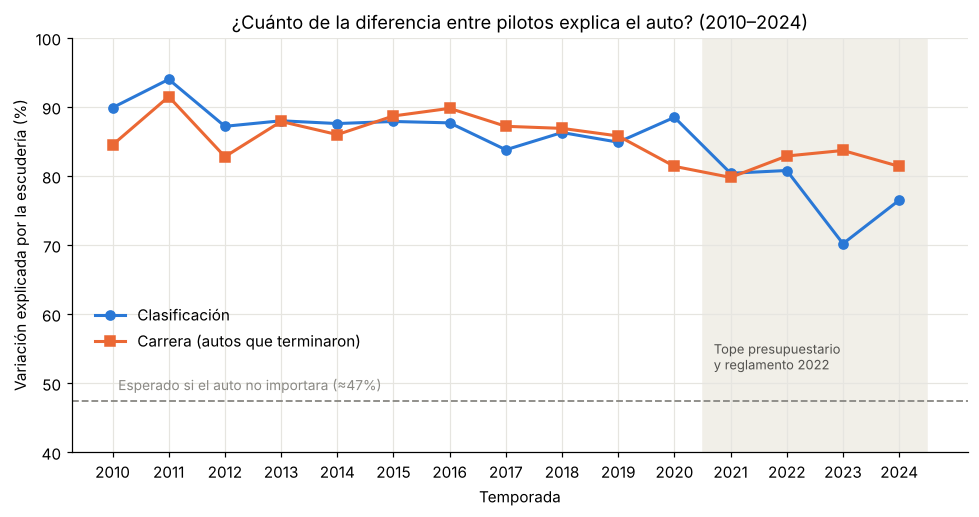

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(peso_auto.index, peso_auto["clasificacion_%auto"], marker="o", lw=2, color=AZUL, label="Clasificación")
ax.plot(peso_auto.index, peso_auto["carrera_%auto"], marker="s", lw=2, color=NARANJA, label="Carrera (autos que terminaron)")
ax.axhline(47.4, color=GRIS, ls="--", lw=1.2)
ax.text(2010.1, 49, "Esperado si el auto no importara (≈47%)", color=GRIS, fontsize=9)
ax.axvspan(2020.5, 2024.5, color="#f1efe8", zorder=0)
ax.text(2020.7, 52, "Tope presupuestario\ny reglamento 2022", fontsize=8.5, color="#52514e")
ax.set_ylim(40, 100)
ax.set_xticks(peso_auto.index)
ax.set_title("¿Cuánto de la diferencia entre pilotos explica el auto? (2010–2024)")
ax.set_xlabel("Temporada")
ax.set_ylabel("Variación explicada por la escudería (%)")
ax.legend(loc="center left", bbox_to_anchor=(0.01, 0.3), frameon=False)
fig.tight_layout()
fig.savefig("graficos/01_peso_auto_por_anio.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.** Las dos líneas quedan siempre muy por encima de la referencia del azar: en cualquier temporada, la escudería explica la mayor parte del orden en que terminan los pilotos. El pico de 2011 coincide con el dominio de Red Bull, y la caída desde 2021 coincide con autos más parejos. En clasificación la caída es más marcada: con autos similares, una vuelta rápida depende más del piloto. La carrera se mantiene más alta porque estrategia, fiabilidad y ritmo de carrera dependen mucho del equipo.

### Gráfico 2 — Comparación entre categorías: duelos de clasificación ganados (barras)

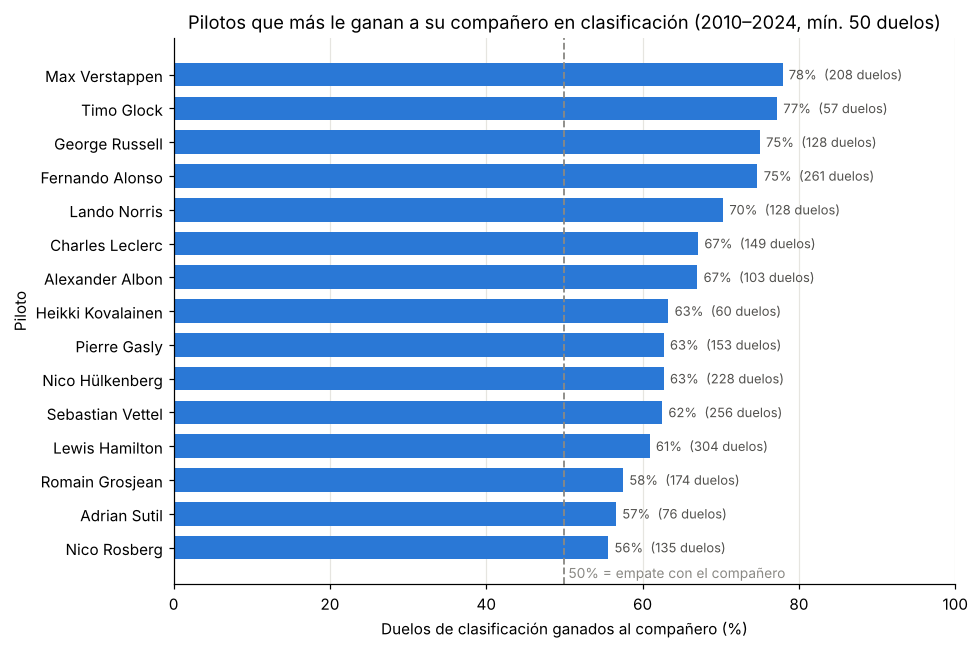

In [29]:
top = duelos.head(15).sort_values("pct_ganados")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["pct_ganados"], color=AZUL, height=0.7)
ax.axvline(50, color=GRIS, ls="--", lw=1.2)
ax.text(50.5, -0.9, "50% = empate con el compañero", color=GRIS, fontsize=9)
for y, (v, n) in enumerate(zip(top["pct_ganados"], top["duelos"])):
    ax.text(v + 0.8, y, f"{v:.0f}%  ({n} duelos)", va="center", fontsize=8.5, color="#52514e")
ax.set_xlim(0, 100)
ax.set_title("Pilotos que más le ganan a su compañero en clasificación (2010–2024, mín. 50 duelos)")
ax.set_xlabel("Duelos de clasificación ganados al compañero (%)")
ax.set_ylabel("Piloto")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig("graficos/02_duelos_companeros.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.** Este gráfico muestra la otra cara de la pregunta: con el mismo auto, algunos pilotos le ganan a su compañero de forma sistemática, en varios equipos y contra distintos compañeros. Ahí está el "talento" medido de la forma más justa posible. Hay que leerlo con cuidado: ganarle a un compañero débil es más fácil que a uno fuerte, así que el porcentaje también depende de con quién compartió equipo cada piloto. El caso de Timo Glock (segundo, en Virgin/Marussia, con compañeros debutantes) lo muestra: un porcentaje alto no lo convierte en el segundo mejor piloto del período.

### Gráfico 3 — Relación entre dos variables: piloto vs. compañero (dispersión)

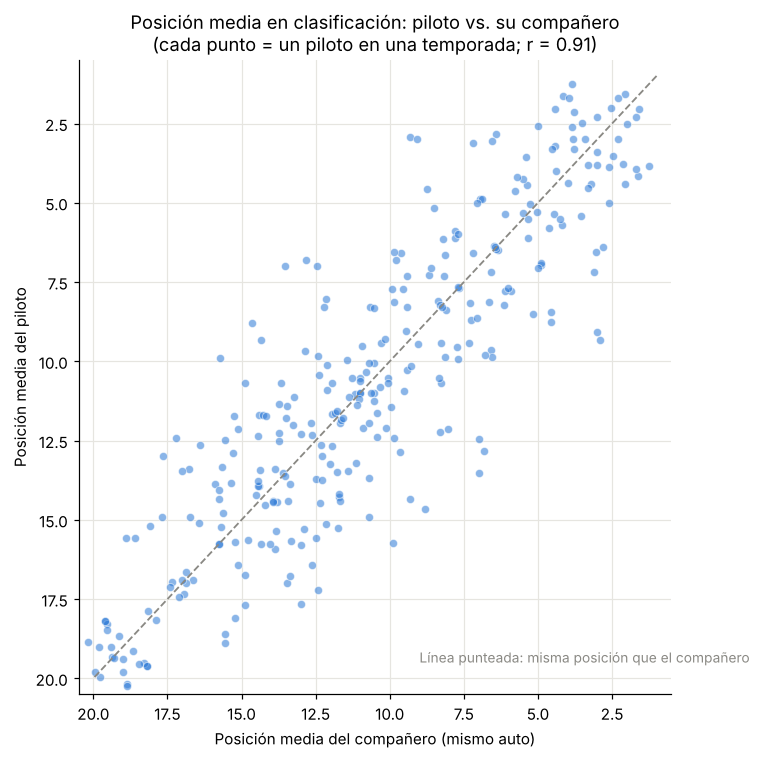

In [30]:
r = pares["pos_media"].corr(pares["pos_media_comp"])
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pares["pos_media_comp"], pares["pos_media"], s=28, color=AZUL, alpha=0.55, edgecolor="white", linewidth=0.6)
ax.plot([1, 20], [1, 20], color=GRIS, ls="--", lw=1.2)
ax.text(9, 19.5, "Línea punteada: misma posición que el compañero", color=GRIS, fontsize=9)
ax.set_xlim(0.5, 20.5); ax.set_ylim(0.5, 20.5)
ax.invert_xaxis(); ax.invert_yaxis()
ax.set_title(f"Posición media en clasificación: piloto vs. su compañero\n(cada punto = un piloto en una temporada; r = {r:.2f})")
ax.set_xlabel("Posición media del compañero (mismo auto)")
ax.set_ylabel("Posición media del piloto")
fig.tight_layout()
fig.savefig("graficos/03_piloto_vs_companero.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretación.** Los puntos se alinean con fuerza sobre la diagonal: si el compañero clasifica adelante, el piloto también, y si el compañero clasifica atrás, el piloto también. La correlación alta es el efecto del auto. La distancia vertical de cada punto a la diagonal es el efecto del piloto: existe, pero suele ser de 1 a 3 posiciones, mientras que el auto mueve los puntos a lo largo de casi toda la grilla.

### Gráfico 4 — Distribución: distancia entre compañeros por temporada (boxplot)

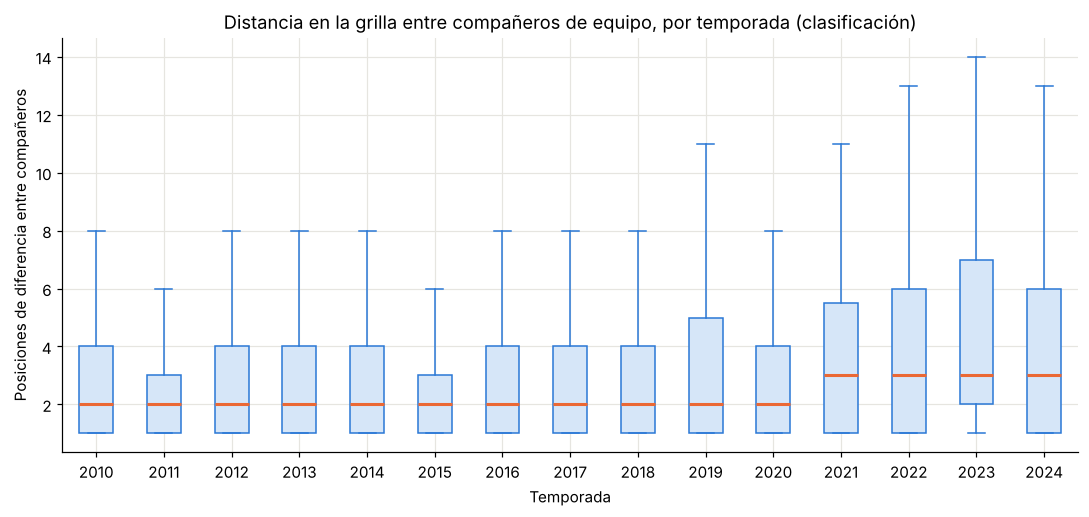

year
2010    2.0
2011    2.0
2012    2.0
2013    2.0
2014    2.0
2015    2.0
2016    2.0
2017    2.0
2018    2.0
2019    2.0
2020    2.0
2021    3.0
2022    3.0
2023    3.0
2024    3.0
Name: brecha, dtype: float64

In [31]:
brecha = (clasif.groupby(["raceId", "constructorId", "year"])["position"]
          .agg(lambda s: s.max() - s.min()).rename("brecha").reset_index())
anios = sorted(brecha["year"].unique())
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.boxplot([brecha.loc[brecha["year"] == a, "brecha"] for a in anios], tick_labels=anios, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor="#d6e6f8", color=AZUL), medianprops=dict(color=NARANJA, lw=2),
           whiskerprops=dict(color=AZUL), capprops=dict(color=AZUL))
ax.set_title("Distancia en la grilla entre compañeros de equipo, por temporada (clasificación)")
ax.set_xlabel("Temporada")
ax.set_ylabel("Posiciones de diferencia entre compañeros")
fig.tight_layout()
fig.savefig("graficos/04_brecha_companeros_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()
brecha.groupby("year")["brecha"].median()

**Interpretación.** En una clasificación típica, dos compañeros con el mismo auto quedan separados por 2 posiciones (mediana) hasta 2020 y por 3 desde 2021; en tres de cada cuatro casos la brecha es de 3 a 7 posiciones o menos, según el año. Comparado con las ~19 posiciones que separan al primero del último, la brecha entre compañeros es chica: el piloto puede ganarle a su compañero, pero rara vez puede sacar a su auto del lugar de la grilla que le corresponde. Que las cajas se estiren desde 2021 es coherente con el gráfico 1: con autos más parejos, un error o una buena vuelta del piloto mueve más lugares.

---
# 6. Respuesta a la pregunta

**¿Qué pesa más en el resultado de una carrera de F1 (2010–2024): el auto o el piloto?**

**El auto, por amplio margen.** Comparando compañeros de equipo:

1. **La escudería explica alrededor del 85% de la variación de posiciones** dentro de cada carrera, tanto en clasificación como en carrera (gráfico 1). Ningún año baja del 70%, muy por encima del ~47% que daría el azar.
2. **El piloto explica el ~15% restante, y ese peso es real y persistente.** Pilotos como Verstappen, Alonso o Russell le ganan la clasificación a su compañero 3 de cada 4 veces, a lo largo de varios equipos (gráfico 2).
3. **Pero el efecto del piloto es chico en posiciones.** La posición media de un piloto y la de su compañero tienen correlación 0,91 (gráfico 3), y la brecha típica entre compañeros es de 2–3 lugares en una grilla de 20 (gráfico 4).
4. **El balance cambió en 2021–2024.** Con el tope presupuestario y el reglamento 2022 los autos quedaron más parejos y el peso del piloto subió: en la clasificación de 2023 llegó a ~30%.

**Limitaciones.** (a) La descomposición atribuye al "auto" todo lo que comparten los compañeros: auto, estrategia, equipo técnico, y también que los mejores pilotos tienden a ir a los mejores autos. Por eso el 85% es una cota superior del efecto del auto. (b) La comparación entre compañeros depende de quién sea el compañero. (c) En carrera excluimos los abandonos, que dependen tanto del auto (roturas) como del piloto (choques). (d) Algunas escuderías cambian de nombre en el dataset (Toro Rosso → AlphaTauri → RB), lo que no afecta la comparación dentro de cada carrera.